# EDA — Clasificador P2 de MiBici

Análisis exploratorio sencillo de los viajes usados para responder:

> ¿Una estación estará en riesgo de quedarse sin bicicletas o sin anclajes en la hora siguiente?

El notebook revisa cobertura, calidad y patrones temporales relevantes para P2. Procesa cada CSV mensual por separado para mantener un consumo moderado de memoria y **no utiliza** `Usuario_Id`, género ni año de nacimiento.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW_DIR = ROOT / "data" / "raw"

trip_files = sorted(RAW_DIR.glob("datos_abiertos_*.csv"))
station_file = RAW_DIR / "nomenclatura_2026_09.csv"

if not trip_files or not station_file.exists():
    raise FileNotFoundError(
        "Faltan los datos crudos. Ejecuta `python -m mibici_ml.dataset download-drive`."
    )

plt.style.use("seaborn-v0_8-whitegrid")
print(f"Archivos mensuales encontrados: {len(trip_files)}")

Archivos mensuales encontrados: 13


## Lectura y agregación

Sólo se leen fechas y estaciones. Los resultados se acumulan mensualmente; para la duración se conserva una muestra reproducible de hasta 10,000 viajes por archivo.

In [2]:
columns = ["Inicio_del_viaje", "Fin_del_viaje", "Origen_Id", "Destino_Id"]
monthly_records = []
hour_counts = pd.Series(0, index=range(24), dtype="int64")
origin_counts = pd.Series(dtype="int64")
observed_stations = set()
duration_samples = []

for file_index, csv_path in enumerate(trip_files):
    trips = pd.read_csv(csv_path, usecols=columns, encoding="latin1", na_values=["NULL"])
    starts = pd.to_datetime(trips["Inicio_del_viaje"], errors="coerce")
    ends = pd.to_datetime(trips["Fin_del_viaje"], errors="coerce")
    durations = (ends - starts).dt.total_seconds() / 60
    station_values = pd.concat([trips["Origen_Id"], trips["Destino_Id"]]).dropna().astype(int)
    observed_stations.update(station_values.tolist())

    hour_counts = hour_counts.add(starts.dt.hour.value_counts(), fill_value=0).astype("int64")
    origin_counts = origin_counts.add(
        trips["Origen_Id"].dropna().astype(int).value_counts(), fill_value=0
    ).astype("int64")
    valid_durations = durations[durations.ge(0) & durations.le(24 * 60)]
    duration_samples.append(
        valid_durations.sample(min(10_000, len(valid_durations)), random_state=42 + file_index)
    )

    monthly_records.append(
        {
            "month": csv_path.stem.removeprefix("datos_abiertos_").replace("_", "-"),
            "trips": len(trips),
            "stations": station_values.nunique(),
            "critical_missing": int(trips[columns].isna().any(axis=1).sum()),
            "same_station": int(trips["Origen_Id"].eq(trips["Destino_Id"]).sum()),
            "negative_duration": int(durations.lt(0).sum()),
            "over_24h": int(durations.gt(24 * 60).sum()),
            "first_start": starts.min(),
            "last_start": starts.max(),
        }
    )

monthly = pd.DataFrame(monthly_records)
duration_sample = pd.concat(duration_samples, ignore_index=True)
monthly

,month,trips,stations,critical_missing,same_station,negative_duration,over_24h,first_start,last_start
0,2025-09,376789,367,0,21323,0,0,2025-09-01 00:01:09,2025-09-30 23:59:53
1,2025-10,420064,368,0,23004,0,0,2025-10-01 00:00:26,2025-10-31 23:59:57
2,2025-11,380328,367,0,21025,0,1,2025-11-01 00:00:07,2025-11-30 23:59:53
3,2025-12,335420,368,0,18691,0,1,2025-12-01 00:01:03,2025-12-31 23:59:08
4,2026-01,357180,368,0,20321,0,0,2026-01-01 00:03:07,2026-01-31 23:58:47
5,2026-02,333756,368,0,24222,0,1,2026-02-01 00:00:01,2026-02-28 23:57:41
6,2026-03,376243,369,0,22385,0,1,2026-03-01 00:00:09,2026-03-31 23:59:02
7,2026-04,351851,368,0,21364,0,0,2026-04-01 00:00:26,2026-04-30 23:59:03
8,2026-05,315895,371,0,22407,0,1,2026-05-01 00:01:04,2026-05-31 23:59:19
9,2026-06,355303,427,0,28896,0,6,2026-06-01 00:06:46,2026-06-30 23:59:58


## Cobertura y volumen

,valor
versión de datos,928ac1753461
meses,13
viajes,4874666
estaciones observadas,471
primer inicio,2025-09-01 00:01:09
último inicio,2026-09-30 23:59:48


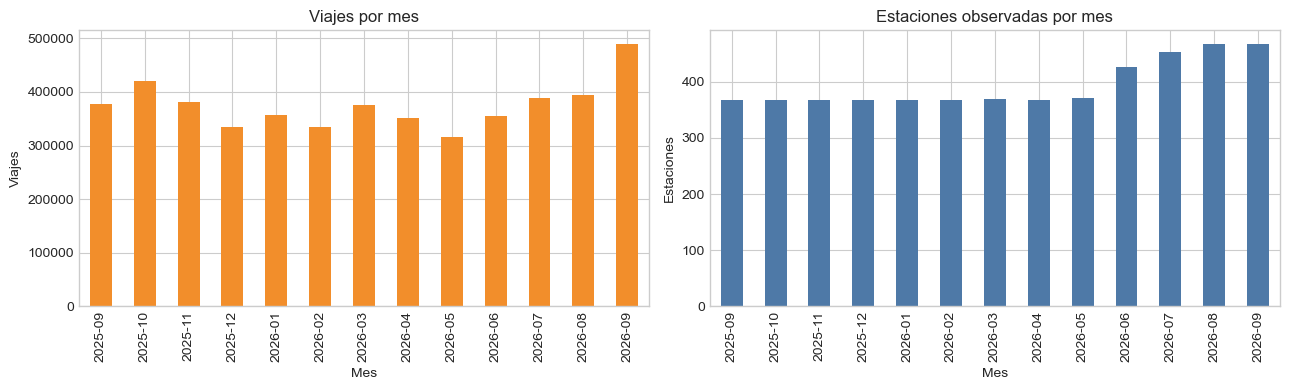

In [3]:
manifest_path = RAW_DIR / "manifest.json"
data_version = "no disponible"
if manifest_path.exists():
    data_version = json.loads(manifest_path.read_text(encoding="utf-8"))["data_version"]

overview = pd.Series(
    {
        "versión de datos": data_version,
        "meses": len(monthly),
        "viajes": int(monthly["trips"].sum()),
        "estaciones observadas": len(observed_stations),
        "primer inicio": monthly["first_start"].min(),
        "último inicio": monthly["last_start"].max(),
    },
    name="valor",
)
display(overview.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
monthly.plot.bar(x="month", y="trips", ax=axes[0], legend=False, color="#F28E2B")
axes[0].set(title="Viajes por mes", xlabel="Mes", ylabel="Viajes")
monthly.plot.bar(x="month", y="stations", ax=axes[1], legend=False, color="#4E79A7")
axes[1].set(title="Estaciones observadas por mes", xlabel="Mes", ylabel="Estaciones")
fig.tight_layout()
plt.show()

## Calidad básica

In [4]:
quality_columns = [
    "month", "critical_missing", "same_station", "negative_duration", "over_24h"
]
display(monthly[quality_columns])

quality_totals = monthly[quality_columns[1:]].sum().rename("total").to_frame()
quality_totals["porcentaje_viajes"] = (
    100 * quality_totals["total"] / monthly["trips"].sum()
)
display(quality_totals)

percentiles = duration_sample.quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
display(percentiles.rename("duración_minutos").to_frame())

,month,critical_missing,same_station,negative_duration,over_24h
0,2025-09,0,21323,0,0
1,2025-10,0,23004,0,0
2,2025-11,0,21025,0,1
3,2025-12,0,18691,0,1
4,2026-01,0,20321,0,0
5,2026-02,0,24222,0,1
6,2026-03,0,22385,0,1
7,2026-04,0,21364,0,0
8,2026-05,0,22407,0,1
9,2026-06,0,28896,0,6


,total,porcentaje_viajes
critical_missing,0,0.000000
same_station,316586,6.494517
negative_duration,0,0.000000
over_24h,13,0.000267


,duración_minutos
0.25,5.666667
0.50,9.383333
0.75,14.733333
0.90,20.700000
0.95,24.450000
0.99,33.283333


Los viajes con origen y destino iguales se excluyen del pipeline conforme al TDD. Las duraciones se examinan sólo como control de calidad; no son una feature de predicción porque la duración futura aún no se conoce al emitir la alerta.

## Patrones de demanda

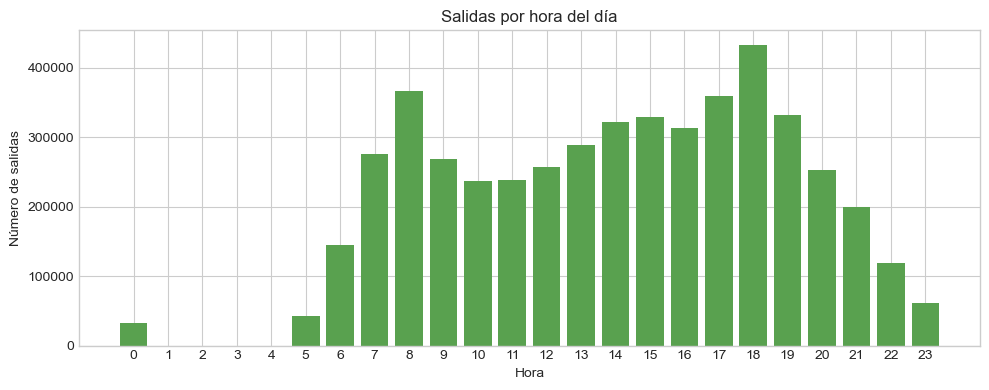

,id,departures,name,dpcapacity
0,51,103829,(GDL-049) Lopez Cotilla / PenitenciarÃ­a,39
1,35,81147,(GDL-033) Av. Hidalgo / C. Pedro Loza,15
2,271,75391,(GDL-198) Av. Alcalde / C. Hospital,31
3,11,69867,(GDL-009) Calz. Federalismo/ C. J. Angulo,23
4,50,58858,(GDL-048) C. Constancio HernÃ¡ndez/ Av. JuarÃ©z,23
5,52,57167,(GDL-050) C.Pedro Moreno /Federalismo,23
6,194,56901,(GDL-127) Av. Vallarta / Av. de Los Arcos,19
7,54,54674,(GDL-052) Av. Juarez /16 de Septiembre,23
8,38,43850,(GDL-036) C. Marcos Castellanos/ C. Morelos,23
9,260,42369,(GDL-187) Av. 16 de Septiembre / C. Priscilia,15


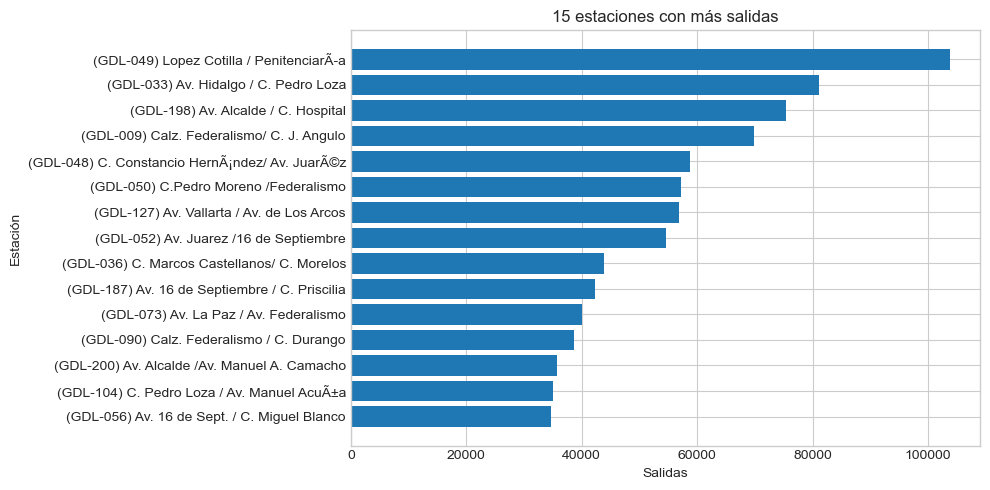

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(hour_counts.index, hour_counts.values, color="#59A14F")
ax.set(
    title="Salidas por hora del día",
    xlabel="Hora",
    ylabel="Número de salidas",
    xticks=range(24),
)
fig.tight_layout()
plt.show()

stations = pd.read_csv(station_file, encoding="latin1")
top_origins = (
    origin_counts.nlargest(15)
    .rename("departures")
    .rename_axis("id")
    .reset_index()
    .merge(stations[["id", "name", "dpcapacity"]], on="id", how="left")
)
display(top_origins)

fig, ax = plt.subplots(figsize=(10, 5))
plot_data = top_origins.sort_values("departures")
ax.barh(plot_data["name"].fillna(plot_data["id"].astype(str)), plot_data["departures"])
ax.set(title="15 estaciones con más salidas", xlabel="Salidas", ylabel="Estación")
fig.tight_layout()
plt.show()

## Capacidad de las estaciones

,capacidad
count,480.000000
mean,17.022917
std,3.843697
min,11.000000
25%,15.000000
50%,15.000000
75%,19.000000
max,39.000000


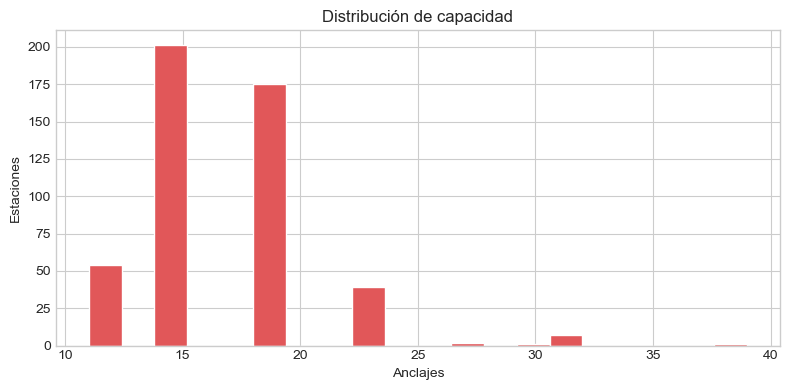

In [6]:
valid_capacity = stations.loc[stations["dpcapacity"].gt(0), "dpcapacity"]
display(valid_capacity.describe().rename("capacidad").to_frame())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(valid_capacity, bins=20, color="#E15759", edgecolor="white")
ax.set(title="Distribución de capacidad", xlabel="Anclajes", ylabel="Estaciones")
fig.tight_layout()
plt.show()

## Hallazgos para P2

In [7]:
peak_hour = int(hour_counts.idxmax())
peak_month = monthly.loc[monthly["trips"].idxmax(), "month"]
station_growth = int(monthly["stations"].iloc[-1] - monthly["stations"].iloc[0])
same_station_rate = 100 * monthly["same_station"].sum() / monthly["trips"].sum()

print(f"• La mayor demanda de salidas ocurre a las {peak_hour:02d}:00.")
print(f"• El mes con más viajes es {peak_month}.")
print(f"• El número mensual de estaciones cambia en {station_growth:+d} durante el periodo.")
print(f"• {same_station_rate:.2f}% de los viajes tienen el mismo origen y destino.")
print("• La capacidad varía entre estaciones, por lo que el objetivo se normaliza con dpcapacity.")
print("• Estos datos permiten construir un proxy de presión, no confirmar desabasto real sin inventario.")

• La mayor demanda de salidas ocurre a las 18:00.
• El mes con más viajes es 2026-09.
• El número mensual de estaciones cambia en +101 durante el periodo.
• 6.49% de los viajes tienen el mismo origen y destino.
• La capacidad varía entre estaciones, por lo que el objetivo se normaliza con dpcapacity.
• Estos datos permiten construir un proxy de presión, no confirmar desabasto real sin inventario.


### Conclusión

El volumen cambia por mes, existe una marcada estacionalidad horaria y la red incorpora estaciones durante el periodo. Esto respalda utilizar variables de calendario, rezagos de demanda y capacidad, así como una partición cronológica. Para observar desabasto real sería necesario complementar los viajes con snapshots de inventario.